## Дипломный проект. Яндекс.Афиша

- Автор: Морозов Сергей Валентинович
- Дата: 31.10.2026


# Исследовательский анализ данных сервиса Яндекс Афиша

## Цель и задачи
**Цель:**  
Выяснить, как изменились пользовательские предпочтения и популярность мероприятий осенью 2024 года, и проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств.

**Задачи:**
1. Загрузить данные и провести предобработку.
2. Проанализировать распределение заказов по сегментам и сезонные изменения.
3. Изучить осеннюю активность пользователей.
4. Выделить ключевые регионы и билетных партнёров.
5. Проверить две статистические гипотезы.


## Описание данных
<font color='#777778'>Исходные данные представлены в датасетах 
 - `final_tickets_orders_df.csv `.
включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. Содержит следующие колонки:  
`order_id` — уникальный идентификатор заказа.  
`user_id` — уникальный идентификатор пользователя.  
`created_dt_msk` — дата создания заказа (московское время).  
`created_ts_msk` — дата и время создания заказа (московское время).  
`event_id` — идентификатор мероприятия из таблицы events.  
`cinema_circuit` — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.  
`age_limit` — возрастное ограничение мероприятия.  
`currency_code` — валюта оплаты, например rub для российских рублей.  
`device_type_canonical` — тип устройства, с которого был оформлен заказ, например mobile для мобильных устройств, desktop для стационарных.  
`revenue` — выручка от заказа.  
`service_name` — название билетного оператора.  
`tickets_count` — количество купленных билетов.  
`total` — общая сумма заказа.  
`days_since_prev` - с количеством дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.  

- `final_tickets_events_df.csv` - содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. Датасет содержит такие поля:  
`event_id` — уникальный идентификатор мероприятия.  
`event_name` — название мероприятия. Аналог поля event_name_code из исходной базы данных.  
`event_type_description` — описание типа мероприятия.  
`event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее.  
`organizers` — организаторы мероприятия.  
`region_name` — название региона.  
`city_name` — название города.  
`venue_id` — уникальный идентификатор площадки.  
`venue_name` — название площадки.  
`venue_address` — адрес площадки.

- `final_tickets_tenge_df.csv ` - содержит информацию о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. Датасет содержит такие поля:  
`nominal` — номинал (100 тенге);  
`data` — дата;  
`curs` — курс тенге к рублю;  
`cdx` — обозначение валюты (kzt).
</font>

## Структура проекта
1. Загрузка данных и знакомство с ними
2. Предобработка данных
3. Исследовательский анализ данных
    - 3.1. Распределение заказов по сегментам и сезонные изменения
    - 3.2. Осенняя активность пользователей
    - 3.3. Популярные события и партнёры
4. Статистический анализ данных
5. Общий вывод и рекомендации

## Шаг 1. Загрузка данных и знакомство с ними
### 1.1. Импорт библиотек и загрузка данных
Подключаем необходимые библиотеки и загружаем три датасета: заказы, мероприятия и курс тенге.

In [1]:
# Импортируем необходимые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
# Загружаем данные
orders_df = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv")
events_df = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_events_df.csv")
tenge_df = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv")

### 1.2. Первичный осмотр
Смотрим размер таблиц, типы данных, пропуски и первые строки каждого датасета.

In [3]:
for name, data in [('orders', orders_df), ('events', events_df), ('tenge', tenge_df)]:
    print(f'--- {name}: {data.shape}')
    data.info()
    display(data.head())


--- orders: (290849, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


--- events: (22427, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


--- tenge: (357, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


### 1.3. Промежуточный вывод по знакомству с данными

- `orders_df` содержит 290 849 заказов и 14 столбцов, `events_df` — 22 427 мероприятий и 11 столбцов, `tenge` — 357 дневных значений курса за 2024 год.
- Типы данных в целом соответствуют описанию, но даты (`created_dt_msk`, `created_ts_msk`) загружены как строки — их нужно привести к datetime.
- Пропуски в `orders_df` есть только в `days_since_prev`, это оговорено в ТЗ. 
- Данные содержат заказы в двух валютах (рубли и тенге), поэтому выручку нужно привести к рублям.
- В `events_df` нет фильмов(указано в ТЗ), поэтому часть заказов может не найти  соответствия в данных о мероприятиях, если эти заказы были в отношении фильмов.

**План предобработки:** проверить пропуски и категории, объединить таблицы, преобразовать типы, проверить дубликаты, обработать выбросы выручки отдельно для рублей и тенге, добавить столбцы `revenue_rub`, `one_ticket_revenue_rub`, `month`, `season`.

## Шаг 2. Предобработка данных
### 2.1. Проверка пропусков
Проверяем пропуски во всех таблицах и уникальность идентификаторов мероприятий.

In [4]:
for name, data in [('orders', orders_df), ('events', events_df), ('tenge', tenge_df)]:
    print(f'-----Пропуски в {name}-----')
    blanks_df = pd.DataFrame({'sum' : data.isna().sum(), 
                              'mean': data.isna().mean()})
    display(blanks_df[blanks_df['sum']>0])

-----Пропуски в orders-----


,sum,mean
days_since_prev,21940,0.075434


-----Пропуски в events-----


,sum,mean


-----Пропуски в tenge-----


,sum,mean


In [5]:
print('Дубликаты event_id в events:', events_df['event_id'].duplicated().sum())
print('Уникальных пользователей в orders:', orders_df['user_id'].nunique())

Дубликаты event_id в events: 0
Уникальных пользователей в orders: 21940


In [6]:
# Берем уникальных пользователей
mask = orders_df['user_id'].unique()
# Суммируем по этим пользователям признак isna() по полю days_since_prev
v_isna = orders_df[orders_df['user_id'].isin(mask)]['days_since_prev'].isna().sum()
print(f'Количество пропусков в колонке days_since_prev для пользователей, у которых был первый заказ {v_isna}')

Количество пропусков в колонке days_since_prev для пользователей, у которых был первый заказ 21940


**Промежуточный вывод:**  
Пропусков в датафреймах events_df и tenge_df не обнаружено, в датафрейме orders_df пропуски обнаружены только в колонке days_since_prev(порядка 7,5%), что не противоречит требованию ТЗ.  
Мы убедились, что пропуски в days_since_prev принадлежат пользователям совершившим <b>первую</b> покупку, поэтому пропуски в days_since_prev объективны и их нужно оставить как есть.  
Дубликатов по ключевому полю event_id в events_df не обнаружено. Количество уникальных пользователей 21940 

### 2.2. Категориальные данные
Изучаем значения в категориальных столбцах, ищем скрытые пропуски и неявные дубликаты, убираем лишние пробелы.

In [7]:
# На всякий случай избавимся от возможных лишних пробелов
for col in ['cinema_circuit', 'currency_code', 'device_type_canonical', 'service_name']:
    orders_df[col] = orders_df[col].str.strip()

for col in ['event_type_description', 'event_type_main', 'region_name', 'city_name', 'venue_name']:
    events_df[col] = events_df[col].str.strip()
# Визуально проверим нет ли неявных дубликатов в категориальных колонках в таблице orders_df
for col in ['cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical', 'service_name']:
    print(orders_df[col].value_counts(dropna=False))
    print()
# Визуально проверим нет ли неявных дубликатов в категориальных колонках в таблице events_df
for col in ['event_type_description', 'event_type_main', 'region_name']:
    print(events_df[col].value_counts(dropna=False))
    print()

print('Регионов:', events_df['region_name'].nunique(), '| городов:', events_df['city_name'].nunique())

cinema_circuit
нет           289451
Другое          1261
КиноСити         122
Киномакс           7
Москино            7
ЦентрФильм         1
Name: count, dtype: int64

age_limit
16    78579
12    62557
0     61487
6     52173
18    36053
Name: count, dtype: int64

currency_code
rub    285780
kzt      5069
Name: count, dtype: int64

device_type_canonical
mobile     232679
desktop     58170
Name: count, dtype: int64

service_name
Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру          

### 2.3. Объединение таблиц и преобразование типов данных
Объединяем заказы с информацией о мероприятиях, приводим даты к datetime и понижаем размерность числовых столбцов.

In [8]:
# Фиксируем размерность до объединения
rows_before = len(orders_df)
df = orders_df.merge(events_df, on='event_id', how='inner')
print(f'Заказов до объединения: {rows_before}, после: {len(df)}, удалено (фильмы): {rows_before - len(df)}')
# Приводим к типу дата
df['created_dt_msk'] = pd.to_datetime(df['created_dt_msk'])
df['created_ts_msk'] = pd.to_datetime(df['created_ts_msk'])
# Приводим к числовому типу с уменьшением размерности 
for col in ['order_id', 'event_id', 'age_limit', 'tickets_count', 'city_id', 'venue_id']:
    df[col] = pd.to_numeric(df[col], downcast='integer')
df['days_since_prev'] = df['days_since_prev'].astype('float32')

df.info()

Заказов до объединения: 290849, после: 290611, удалено (фильмы): 238
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290611 non-null  int32         
 1   user_id                 290611 non-null  object        
 2   created_dt_msk          290611 non-null  datetime64[ns]
 3   created_ts_msk          290611 non-null  datetime64[ns]
 4   event_id                290611 non-null  int32         
 5   cinema_circuit          290611 non-null  object        
 6   age_limit               290611 non-null  int8          
 7   currency_code           290611 non-null  object        
 8   device_type_canonical   290611 non-null  object        
 9   revenue                 290611 non-null  float64       
 10  service_name            290611 non-null  object        
 11  tickets_count         

**Промежуточный вывод:**  
В результате объединения датафреймов, используя тип объединения `inner` в итоговом датасете стало на 238 строк меньше. Это объясняется тем,   
что при подготовке датасетов с помощью SQL в датасете events исключены события с типом `фильм`, а в таблице заказы(orders) строки с заказами на данный тип события остались. Таким образом намеренно или нет нарушена ссылочная целостность исходных датасетов. Для бОльшей убедительности я проверил путем прямых запросов(sql) к БД, что эти 238 записей относятся именно к событиям с типом `фильм`.

### 2.4. Проверка дубликатов
Ищем явные дубликаты по номеру заказа и неявные дубликаты бронирований без учёта идентификатора заказа.

In [9]:
print('Явные дубликаты по order_id:', df['order_id'].duplicated().sum())

# неявные дубликаты: одинаковые заказы без учёта order_id , колонку days_since_prev тоже включаем в поиск наличия дубликатов
# dup_cols = [col for col in df.columns if col not in ['order_id', 'days_since_prev']] закомментировал старый код
# исправленные код
dup_cols = [col for col in df.columns if col not in ['order_id']]
print('Неявные дубликаты:', df.duplicated(subset=dup_cols).sum())

df = df.drop_duplicates(subset=dup_cols).reset_index(drop=True)
print('Строк после удаления дубликатов:', len(df))

Явные дубликаты по order_id: 0
Неявные дубликаты: 30
Строк после удаления дубликатов: 290581


### 2.5. Анализ выбросов
Изучаем распределение выручки с заказа и числа билетов отдельно для рублей и тенге.

In [10]:
print('Распределение выручки в рублях')
print(df.loc[df['currency_code'] == 'rub', 'revenue'].describe(percentiles=[0.95, 0.99]).round(2))
print()
print('Распределение выручки в тенге')
print(df.loc[df['currency_code'] == 'kzt', 'revenue'].describe(percentiles=[0.95, 0.99]).round(2))
print()
print('Распределение по количеству билетов')
print(df['tickets_count'].describe(percentiles=[0.99]))


Распределение выручки в рублях
count    285512.00
mean        548.04
std         871.78
min         -90.76
50%         346.70
95%        1607.62
99%        2570.80
max       81174.54
Name: revenue, dtype: float64

Распределение выручки в тенге
count     5069.00
mean      4995.21
std       4916.75
min          0.00
50%       3698.83
95%      13784.26
99%      17617.24
max      26425.86
Name: revenue, dtype: float64

Распределение по количеству билетов
count    290581.000000
mean          2.754337
std           1.170614
min           1.000000
50%           3.000000
99%           6.000000
max          57.000000
Name: tickets_count, dtype: float64


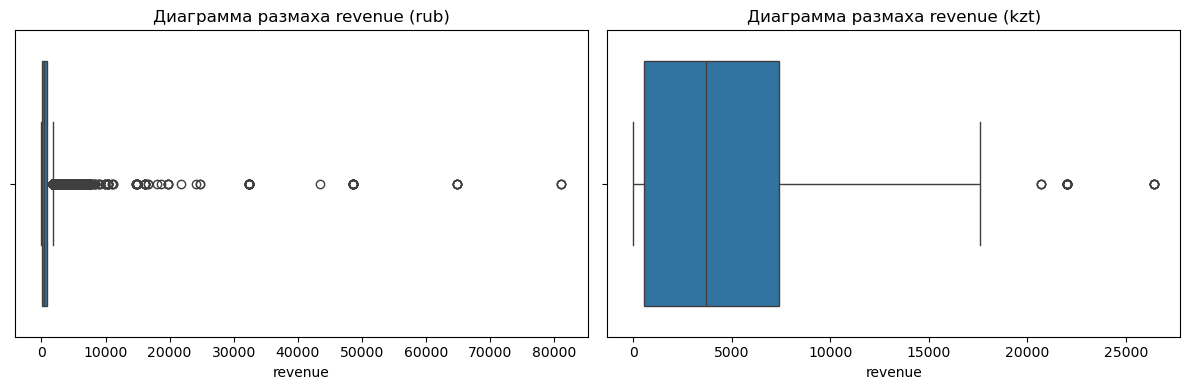

In [11]:
# Отрисовка распределений
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, cur in enumerate(['rub', 'kzt']):
    part = df[df['currency_code'] == cur]
    sns.boxplot(x=part['revenue'], ax=axes[i])
    axes[i].set_title(f'Диаграмма размаха revenue ({cur})')
plt.tight_layout()
plt.show()

**Промежуточный вывод:**  
На диаграммах размаха видны очевидные выбросы в выручке в рублях и тенге. Статистика(метод describe) укуазывает, что максимальное значение рублевой выручки 81174.54, в то время как медианная выручка равна 346.7 руб. Для выручки в тенге максимальное значение 26425, а медианное 3698. Очевидно, что выбросы нужно удалить.  
Для распределение по количеству билетов видно, что максимальное 57 билетов, в то время как медианное значение равно трем. В этом показателе выбросы тоже необходимо устранить.

In [12]:
# Создаем временный дата фрейм по регионам
df_reg1 = df[['currency_code', 'region_name','revenue', 'tickets_count']].copy()

# считаем выручку с одного билета
df_reg1['rev_by_ticket'] = df_reg1['revenue']/df_reg1['tickets_count']

# удалим ненужные колнки
df_reg1 = df_reg1.drop(columns=['revenue', 'tickets_count'])

# отразим регионы с экстремальными показателями по выручке за один билет в разрезе валют
for cur in ['rub', 'kzt']:
    print(f'---Регион c минимальной выручкой за билет в валюте: {cur}---')
    print(df_reg1.loc[df_reg1[df_reg1['currency_code'] == cur]['rev_by_ticket'].idxmin(), ['region_name', 'rev_by_ticket']])
    print(f'---Регион c максимальной выручкой за билет в валюте: {cur}---')
    print(df_reg1.loc[df_reg1[df_reg1['currency_code'] == cur]['rev_by_ticket'].idxmax(), ['region_name', 'rev_by_ticket']])
    # 99-й перцентиль
    p99_val = df_reg1[df_reg1['currency_code'] == cur]['rev_by_ticket'].quantile(0.99)
    print(f'Топ 5 регионов, в которых есть превышения 99 процентиля в валюте: {cur} ')
    top_p99 =  df_reg1[(df_reg1['currency_code'] == cur) & (df_reg1['rev_by_ticket'] >= p99_val)]['region_name'].value_counts().head(5)
    print(top_p99) 


---Регион c минимальной выручкой за билет в валюте: rub---
region_name      Медовская область
rev_by_ticket              -18.152
Name: 226253, dtype: object
---Регион c максимальной выручкой за билет в валюте: rub---
region_name      Североярская область
rev_by_ticket                21757.54
Name: 78587, dtype: object
Топ 5 регионов, в которых есть превышения 99 процентиля в валюте: rub 
region_name
Каменевский регион      1997
Североярская область     393
Светополянский округ     158
Широковская область      112
Лесоярская область        60
Name: count, dtype: int64
---Регион c минимальной выручкой за билет в валюте: kzt---
region_name      Шанырский регион
rev_by_ticket                 0.0
Name: 232938, dtype: object
---Регион c максимальной выручкой за билет в валюте: kzt---
region_name      Верхоречная область
rev_by_ticket                4404.31
Name: 1710, dtype: object
Топ 5 регионов, в которых есть превышения 99 процентиля в валюте: kzt 
region_name
Верхоречная область    728
N

<b>Промежуточный вывод</b>  
   Видим, что минимальная выручка с одного билета в рубях -18.15 р в Медовской области. Видимо это возврат. В тенге 0 kzt. Максимальная выручка в рублях за один билет 21757 р. в Свероярской области. Топ 2 регионов, в которых есть превышения 99 процентиля в валюте: rub - "Каменевский район" и "Северярская область", для kzt, это только "Верхоречная область"

### 2.6. Фильтрация выбросов
Отбираем значения выручки по 99-му процентилю отдельно для каждой валюты.

In [13]:
# Надо быть осторожным с  перезапуском данной ячейки, так повторный запуск уменьшает каждый раз размер датафрейма 
# на количество строк, в которых revenue меньше 99 процентиля. Её нужно запускать один раз.
rows_before = len(df)
quantil99 = df.groupby('currency_code')['revenue'].quantile(0.99)
for name, val in quantil99.items():
    df.drop(index=df.loc[(df['currency_code']==name)&(df['revenue']>val)].index, inplace=True)
df = df.reset_index(drop=True)
print(f'Удалено выбросов: {rows_before - len(df)}')
print(df['currency_code'].value_counts())

Удалено выбросов: 2829
currency_code
rub    282712
kzt      5040
Name: count, dtype: int64


В результате фильтрации выбросов было удалено 2829 записей в исследуемом датафрейме

### 2.7. Создание новых столбцов
Приводим выручку к рублям и добавляем выручку с одного билета, месяц и сезон заказа.

Нужно убедиться в корректности данных с курсом - нет ли дубликатов по дате, по всем ли датам есть курс, адекватные ли там значения, какой номинал, представлены ли только тенге, а уже потом переходить к присоединению.
Перед созданием новых столбцов и  вычисления 'revenue_rub' проверим корректность датасета с курсом tenge_df

In [14]:
v_len = len(tenge_df)
# Проверка на наличие полных дубликатов
print(f'Количество полных дубликатов = {tenge_df.duplicated().sum()}')

# Проверка на наличие  дубликатов по дате
print(f'Количество дубликатов по дате = {tenge_df.duplicated(subset = 'data').sum()}')

# Проверка наличия пропусков
print(f'Количество пропусков по всем полям в tenge_df = {sum(tenge_df.isna().sum())}')

# Проверка на предмет наличия пропусков в самих курсах
col = [c for c in tenge_df.columns if c != 'data']
print(f'Пропуски в курсах на дату = {sum(tenge_df[col].isna().sum())}')

# Проверим корректность корректность номиналов: все должны быть равны 100
res = tenge_df[tenge_df['nominal']==100]['nominal'].count()
print('Все номиналы равны 100' if v_len == res else 'Не все номиналы равны 100')

# Проверим тип валюты
if v_len - tenge_df[tenge_df['cdx']=='kzt']['cdx'].count() == 0:
    print('Все строки датафрейма tenge_df представляют курс казахского тенге kzt')
else:
    print('Не все строки датафрейма tenge_df представляют курс казахского тенге kzt')
# приведем к типу дата колонку 'data'
tenge_df['data'] = pd.to_datetime(tenge_df['data'])

# проверим интервал дат и пропуски
start = pd.Timestamp('2024-06-01')# Начало исследуемого интревала
end = pd.Timestamp('2024-10-31') # Конец исследуемого интервала
all_dates = pd.date_range(start, end, freq='D')
requared_range = tenge_df[(tenge_df['data'] >= start) & (tenge_df['data'] <= end)][['data', 'curs']]
missing_days = all_dates.difference(requared_range['data'])
print(f'Представленые курсы казахского тенге находятся в нужном диапазоне дат от {start.date()} до {end.date()}' if len(missing_days) == 0 else 'Не все курсы предствлены в нужном диапазоне')

# Проверим на адекватность курсы
print('Статистика по полю curs в датафрейме tenge_df в исследуемомом интервале дат')
print(requared_range.curs.describe())

Количество полных дубликатов = 0
Количество дубликатов по дате = 0
Количество пропусков по всем полям в tenge_df = 0
Пропуски в курсах на дату = 0
Все номиналы равны 100
Все строки датафрейма tenge_df представляют курс казахского тенге kzt
Представленые курсы казахского тенге находятся в нужном диапазоне дат от 2024-06-01 до 2024-10-31
Статистика по полю curs в датафрейме tenge_df в исследуемомом интервале дат
count    153.000000
mean      19.052050
std        0.642594
min       17.848600
25%       18.505700
50%       19.027600
75%       19.684100
max       20.277300
Name: curs, dtype: float64


Датафрейм проверен на наличие дубликатов и пропусков. Курсы представлены во всем наблюдаемомом диапазоне и не содержит пропусков. 
Статистиа по самим значениям курса адекватная: среднее значение почти равно медианному, отклонения минимального значения от макимального незначительны.

<b>Вывод:</b> можно приступать к объединению датафрейма tenge_df к основному датафрейму.


In [15]:
# приведем к типу дата
tenge_df['data'] = pd.to_datetime(tenge_df['data'])
# Объединяем датафреймы
df = df.merge(tenge_df[['data', 'curs', 'nominal']], left_on='created_dt_msk', right_on='data', how='left')
# Создаем колонку 'revenue_rub'
df['revenue_rub'] = df['revenue']
# Высчитываем выручку в рублях по курсу тенге
df.loc[df['currency_code'] == 'kzt', 'revenue_rub'] = df['revenue'] * df['curs'] / df['nominal']
# Визуальная проверка
display(df[df['currency_code']=='kzt'][['revenue','currency_code', 'curs', 'nominal', 'revenue_rub']].head(2))
display(df[df['currency_code']=='rub'][['revenue','currency_code', 'curs', 'nominal', 'revenue_rub']].head(2))

,revenue,currency_code,curs,nominal,revenue_rub
70,518.10,kzt,19.0125,100,98.503762
88,347.18,kzt,18.9330,100,65.731589


,revenue,currency_code,curs,nominal,revenue_rub
0,1521.94,rub,18.6972,100,1521.94
1,289.45,rub,18.3419,100,289.45


In [16]:
# Создаем функцию определения сезона
def get_season(month=0):
    if month in [12,1,2]:
        return 'зима'
    elif month in range(3,6):
        return 'весна'
    elif month in range(6, 9):
        return 'лето'
    elif month in range(9, 12):
        return 'осень'
    else:
        return 'неизвестно'

In [17]:
# Удаляем ненужные столбцы
df = df.drop(columns=['data', 'curs', 'nominal'])
# считаем выручку на один билет и создаем новое поле
df['one_ticket_revenue_rub'] = df['revenue_rub'] / df['tickets_count']
# Создаем колонку месяц
df['month'] = df['created_dt_msk'].dt.month
# Создаем колонку - сезон, используя функцию get_season
df['season'] = df['month'].apply(get_season)
print('Пропусков в revenue_rub:', df['revenue_rub'].isna().sum())
display(df[['currency_code', 'revenue', 'revenue_rub', 'tickets_count', 'one_ticket_revenue_rub', 'month', 'season']].sample(5, random_state=42))

Пропусков в revenue_rub: 0


,currency_code,revenue,revenue_rub,tickets_count,one_ticket_revenue_rub,month,season
271849,rub,300.85,300.85,1,300.850000,10,осень
243485,rub,675.39,675.39,2,337.695000,8,лето
115921,rub,24.52,24.52,3,8.173333,6,лето
215825,rub,1786.60,1786.60,4,446.650000,9,осень
24221,rub,288.29,288.29,3,96.096667,10,осень


### 2.8. Проверка итоговых данных
Оцениваем, сколько данных осталось после фильтрации, и проверяем период и охват.

In [18]:
print(f'Осталось строк после предобработки: {len(df)}')
print(f'Доля от исходных данных: {len(df) / len(orders_df):.1%}')
print('Период:', df['created_dt_msk'].min().date(), '-', df['created_dt_msk'].max().date())
print('Уникальных пользователей:', df['user_id'].nunique(), '| Уникальных мероприятий:', df['event_id'].nunique())
print(df['season'].value_counts())

Осталось строк после предобработки: 287752
Доля от исходных данных: 98.9%
Период: 2024-06-01 - 2024-10-31
Уникальных пользователей: 21843 | Уникальных мероприятий: 22359
season
осень    168631
лето     119121
Name: count, dtype: int64


### 2.9. Промежуточный вывод по предобработке

- Пропуски есть только в `days_since_prev` (это первые заказы пользователей), остальные столбцы заполнены полностью.
- Таблицы объединены по `event_id`. 238 заказов не нашли пару в `events` — это фильмы, исключённые из выгрузки. Строки удалены, так как для них нет информации о типе мероприятия, региона и площадки.
- Типы данных: даты приведены к `datetime`, целочисленные столбцы понижены по размерности, что снизило объём занимаемой памяти.
- Явных дубликатов по `order_id` нет. Неявные дубликаты (одинаковые заказы без учёта `order_id`) составили 30 строк, они удалены как повторная запись одного бронирования.
- В `revenue` обнаружены выбросы (максимум в рублях около 81 тыс. при медиане около 347 руб.). Выбросы исключены по 99-му проценту отдельно для рублей (порог около 2 571 руб.) и тенге (порог около 17 617 тенге).
- Столбец `revenue_rub` создан конвертацией тенге по курсу на дату заказа (курс задан за 100 тенге).
- В `tickets_count` медиана равна 3 билетам, 99-й процентиль — 6, максимум — 57. Единичные крупные заказы оставлены, так как по заданию выбросы отбираются по выручке.
- В `revenue` есть нулевые и отрицательные значения (минимум -90,76 руб.), вероятно возвраты и бесплатные билеты. Их оставили без изменений, так как отдельной обработки в задании нет.

**Новые столбцы:** `revenue_rub` — выручка в рублях, `one_ticket_revenue_rub` — выручка с одного билета, `month` — месяц заказа, `season` — сезон (лето/осень).

**Итог:** после предобработки осталось 287 752 заказов (98,9% от исходных 290 849). Данные охватывают период с июня по октябрь 2024 года: лето (июнь-август) и осень (сентябрь-октябрь).

## Шаг 3. Исследовательский анализ данных
### 3.1. Распределение заказов по сегментам и сезонные изменения

#### 3.1.1. Динамика заказов по месяцам
Считаем число заказов в каждом месяце и проверяем, растёт ли спрос от июня к осени.

month
6     34164
7     40407
8     44550
9     69352
10    99279
Name: order_id, dtype: int64


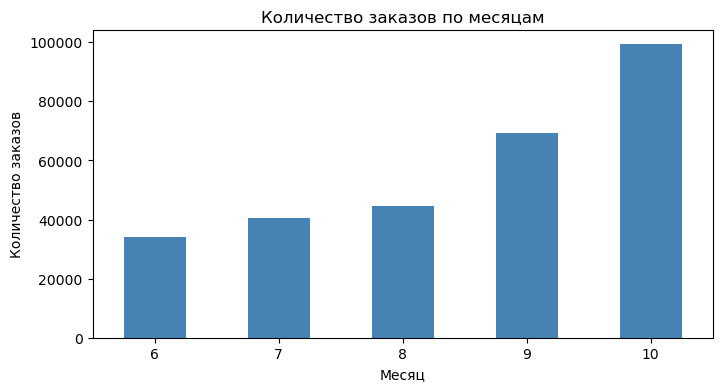

In [19]:
monthly = df.groupby('month')['order_id'].count()
print(monthly)

plt.figure(figsize=(8, 4))
monthly.plot(kind='bar', color='steelblue')
plt.title('Количество заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.xticks(rotation=0)
plt.show()

#### 3.1.2. Распределение заказов по сегментам: лето и осень
Сравниваем доли заказов летом и осенью по типу мероприятия, устройству и возрастному ограничению.

season,лето,осень,прирост лето-осень
event_type_main,,,
выставки,2.03,1.44,-0.59
другое,27.17,19.70,-7.47
концерты,42.62,37.21,-5.41
спорт,2.52,11.20,8.68
стендап,5.33,4.11,-1.22
театр,20.10,25.34,5.24
ёлки,0.23,1.00,0.77


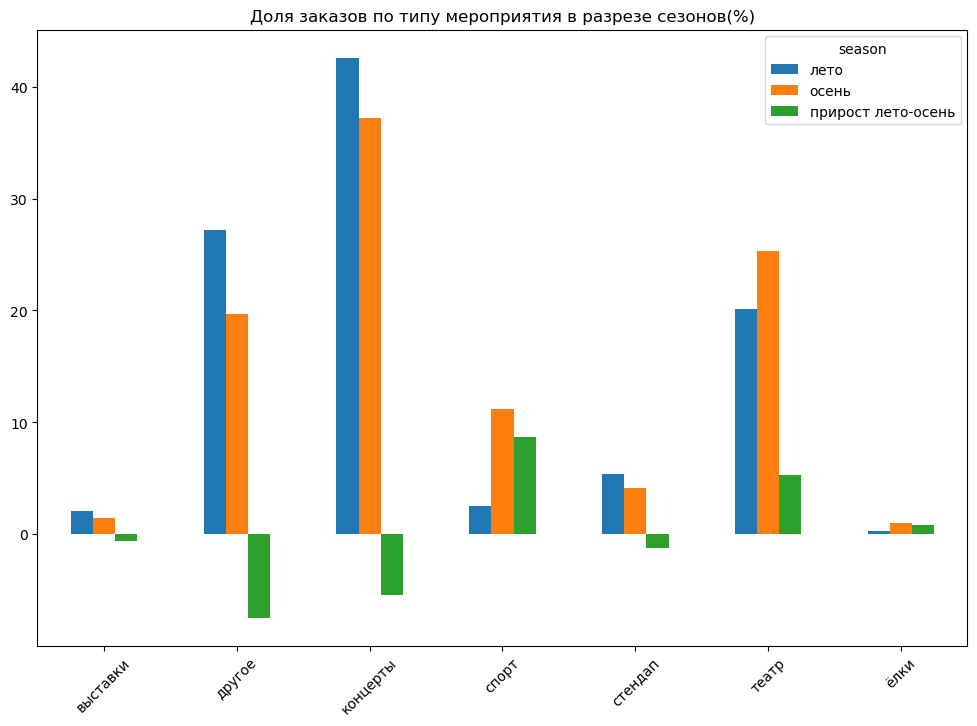

In [20]:
# Доля заказов по типу мероприятия в разрезе сезонов(%)
df_event_type = df.groupby('event_type_main')['season'].value_counts().unstack()
df_event_type_norm = df_event_type.div(df_event_type.sum(axis=0), axis=1) * 100
df_event_type_norm = df_event_type_norm.round(2)
df_event_type_norm['прирост лето-осень'] = df_event_type_norm['осень'] - df_event_type_norm['лето']
display(df_event_type_norm)
df_event_type_norm.plot(kind='bar', title = 'Доля заказов по типу мероприятия в разрезе сезонов(%)', xlabel = '', figsize=(12, 8), rot=45)
plt.show()

season,лето,осень,прирост лето-осень
device_type_canonical,,,
desktop,19.358467,20.342049,0.983581
mobile,80.641533,79.657951,-0.983581


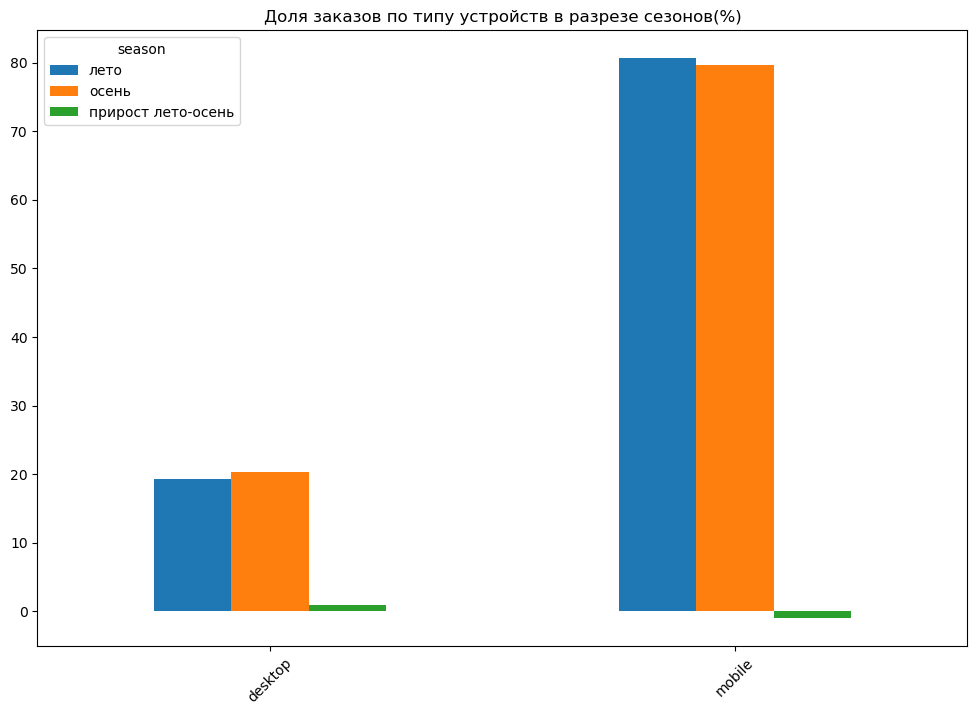

In [21]:
#Доля заказов по типу устройств в разрезе сезонов(%)
df_device_type_norm = df.groupby('device_type_canonical')['season'].value_counts().unstack().div(df_event_type.sum(axis=0), axis=1) * 100
df_device_type_norm['прирост лето-осень'] = df_device_type_norm['осень'] - df_device_type_norm['лето']
display(df_device_type_norm)
df_device_type_norm.plot(kind='bar', title = 'Доля заказов по типу устройств в разрезе сезонов(%)', xlabel = '', figsize=(12, 8), rot=45)
plt.show()

season,лето,осень,прирост лето-осень
age_limit,,,
0,17.968284,23.618433,5.650149
6,18.194105,17.624280,-0.569825
12,20.537101,22.097361,1.560260
16,28.337573,26.221157,-2.116415
18,14.962937,10.438769,-4.524168


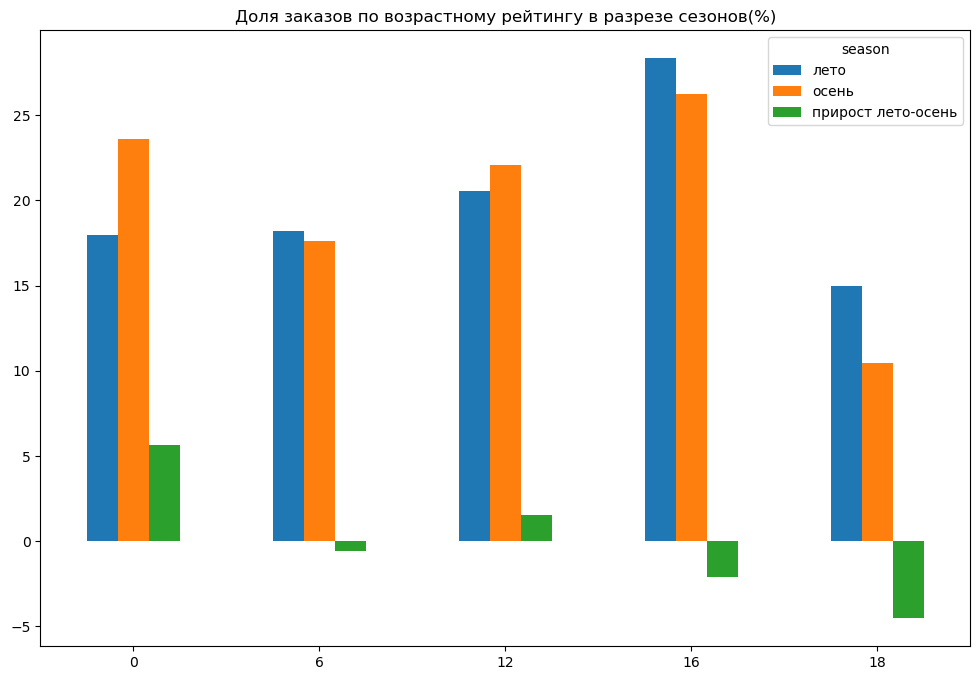

In [22]:
# По категории мероприятия по возрастному рейтингу age_limit
df_age_limit_norm = df.groupby('age_limit')['season'].value_counts().unstack().div(df_event_type.sum(axis=0), axis=1) * 100
df_age_limit_norm['прирост лето-осень'] = df_age_limit_norm['осень'] - df_age_limit_norm['лето']
display(df_age_limit_norm)
df_age_limit_norm.plot(kind='bar', title = 'Доля заказов по возрастному рейтингу в разрезе сезонов(%)', xlabel = '', figsize=(12, 8), rot=0)
plt.show()

#### 3.1.3. Изменение выручки с одного билета
Считаем среднюю выручку с одного билета по типам мероприятий летом и осенью и смотрим относительное изменение.

In [23]:
# Изменение выручки с продажи одного билета в зависимости от типа мероприятия летом и осенью. Подготовка данных
df_event_type_rev_of_ticket = df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub'].mean().unstack()
df_event_type_rev_of_ticket['change_relative'] = round(100 *(df_event_type_rev_of_ticket['осень'] - 
                                                  df_event_type_rev_of_ticket['лето'])/df_event_type_rev_of_ticket['лето'], 2)
df_event_type_rev_of_ticket = df_event_type_rev_of_ticket.sort_values('change_relative')
display(df_event_type_rev_of_ticket.round(2))


season,лето,осень,change_relative
event_type_main,,,
театр,214.14,175.97,-17.82
ёлки,271.44,229.59,-15.42
концерты,304.79,268.36,-11.95
другое,77.43,76.12,-1.70
спорт,50.76,49.97,-1.56
выставки,86.42,90.60,4.85
стендап,218.52,231.12,5.77


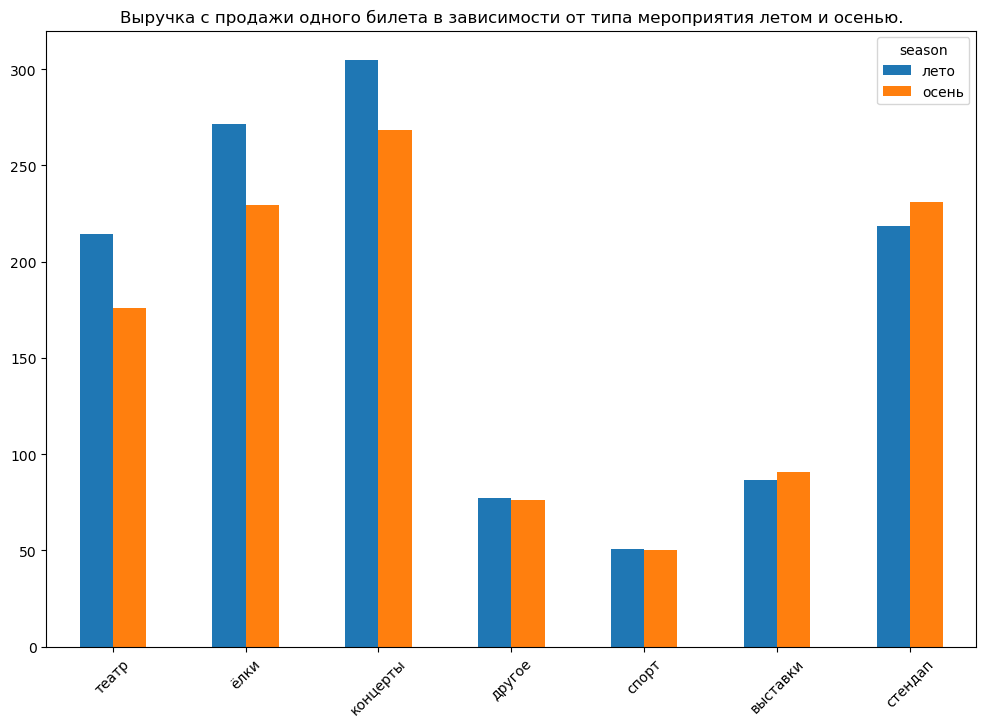

In [24]:
# Визуализация средней выручки с одного билета в разрезе сезонов
df_event_type_rev_of_ticket[['лето', 'осень']].plot(kind='bar', xlabel='', figsize=(12, 8), rot=45,
                                                   title='Выручка с продажи одного билета в зависимости от типа мероприятия летом и осенью.')
plt.show()

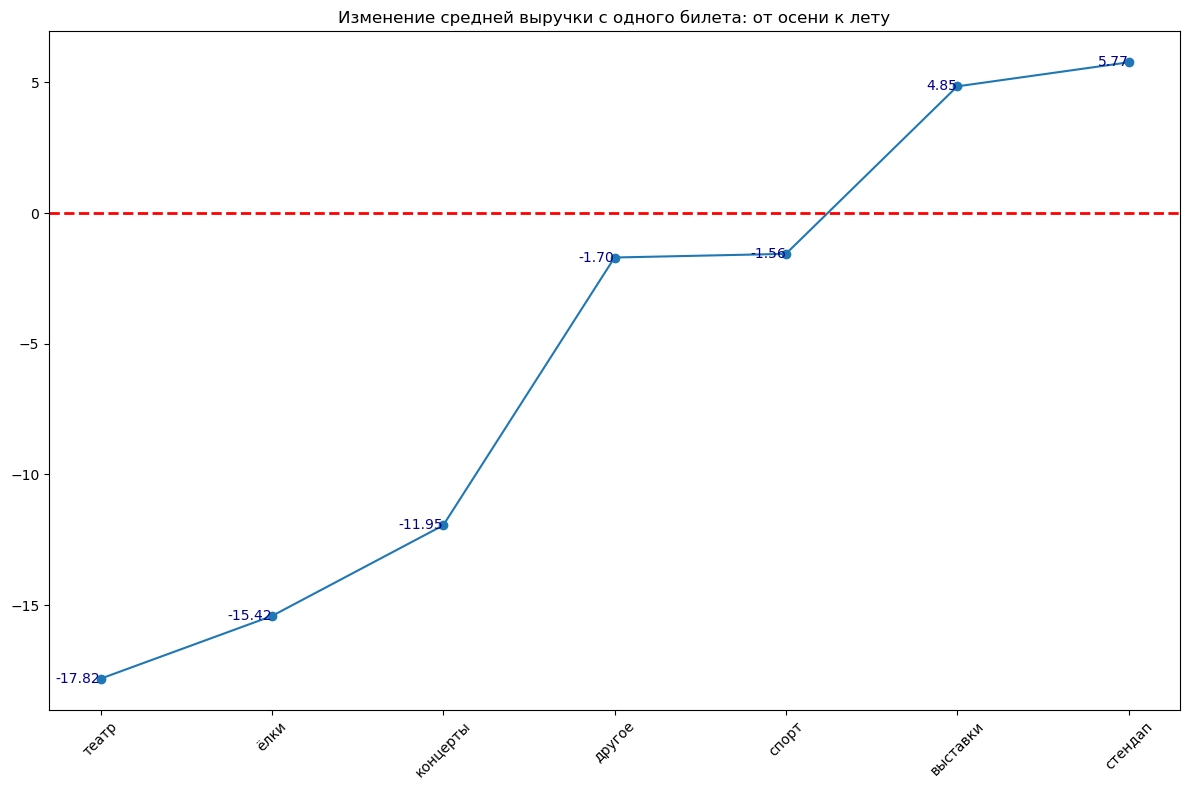

season
лето     209.3
осень    178.1
Name: one_ticket_revenue_rub, dtype: float64


In [25]:
# Визуализация  изменения осенних значений по сравнению с летними
ax = df_event_type_rev_of_ticket[['change_relative']].plot(kind='line', xlabel='', figsize=(12, 8), rot=45,
                                                   title='Изменение средней выручки с одного билета: от осени к лету', 
                                                   legend=False, marker='o')

x_vals = range(len(df_event_type_rev_of_ticket))          
y_vals = df_event_type_rev_of_ticket['change_relative']   

# Добавляем подписи к каждой точке
for i, val in enumerate(y_vals):
    ax.text(
        i, val,
        f'{val:.2f}',          
        ha='right',            
        va='center',           
        fontsize=10,
        color='darkblue'
    )
ax.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Нулевой уровень')
plt.tight_layout()
plt.show()
print(df.groupby('season')['one_ticket_revenue_rub'].mean().round(1))

#### 3.1.4. Промежуточный вывод по разделу 3.1 

**Динамика заказов.** Число заказов растёт каждый месяц: с 34 164 в июне до 99 260 в октябре (почти в 3 раза). Самый заметный скачок приходится на сентябрь (+56% к августу), в октябре рост продолжился (+43% к сентябрю). Данных за ноябрь нет, поэтому проверить рост до ноября нельзя — увеличение подтверждается для периода июнь-октябрь.

**Структура заказов (доли, лето -> осень):**
- Типы мероприятий: сильнее всего выросла доля спорта (2,5% -> 11,2%) и театра (20,1% -> 25,3%), также выросла доля ёлок (0,2% -> 1,0%). Доли категории «другое» (27,2% -> 19,7%) и концертов (42,6% -> 37,2%) снизились, но концерты остаются самым популярным типом.
- Устройства: распределение практически не изменилось — около 80% заказов делают с мобильных устройств, 20% со стационарных.
- Возрастные ограничения: выросла доля 0+ (18,0% -> 23,6%) и 12+ (20,5% -> 22,1%), снизилась доля 18+ (15,0% -> 10,4%) и 16+ (28,3% -> 26,2%). 

**Выручка с одного билета.** Средняя выручка с билета в целом упала с 209,2 до 178,0 руб. (около -15%). По типам мероприятий: театр -17,8%, ёлки -15,4%, концерты -12,0%; практически не изменились спорт (-1,6%) и «другое» (-1,7%); выросли выставки (+4,8%) и стендап (+5,8%).

**Вывод.** Осенью растёт число заказов и меняется структура спроса: больше театра, спорта и детских мероприятий. Снижение средней стоимости билета связано как с удешевлением билетов на театр и концерты, так и со сдвигом структуры: растёт доля дешёвого спорта (около 50 руб. за билет) и падает доля дорогих концертов (около 270-300 руб.).

### 3.2. Осенняя активность пользователей

#### 3.2.1. Динамика активности по дням
Считаем по дням число заказов, DAU, заказы на одного пользователя и среднюю выручку с билета.

,orders,dau,avg_ticket_price,orders_per_user
count,61.00,61.00,61.00,61.00
mean,2764.44,923.59,183.24,2.96
std,967.86,143.34,21.78,0.76
min,1327.00,564.00,80.35,2.33
25%,2314.00,822.00,178.05,2.70
50%,2650.00,946.00,186.97,2.78
75%,2910.00,1025.00,196.21,2.92
max,7289.00,1272.00,209.38,6.63


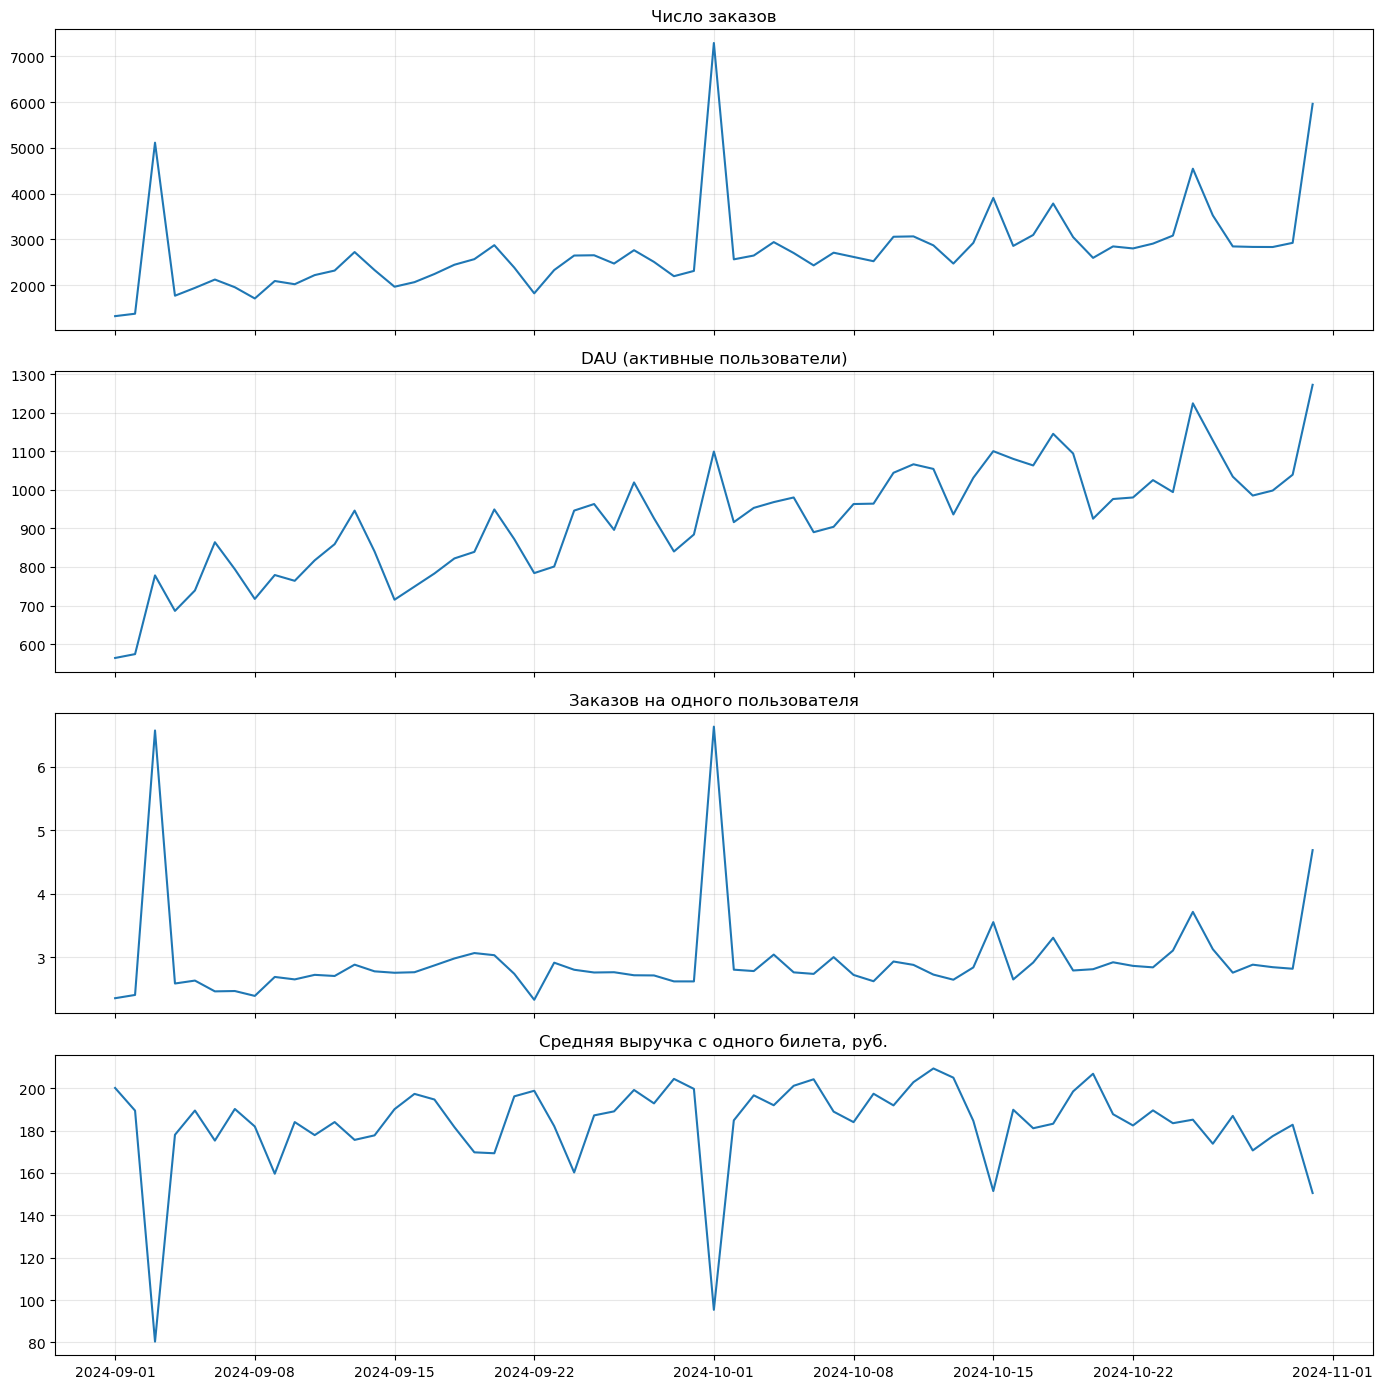

Первая неделя (заказы и dau): {'orders': 2232.0, 'dau': 714.0}
Последняя неделя (заказы и dau): {'orders': 3640.0, 'dau': 1097.0}
Медианный DAU, первые 30 дней: 819.5 | остальные дни: 1025.0


In [26]:
# Фильтруем по осени
autumn_df = df[df['season'] == 'осень']
# Создаем новый датафрейм с группировкой по дням и требуемыми агрегациями
daily_df = autumn_df.groupby('created_dt_msk').agg(orders=('order_id', 'count'),
                                             dau=('user_id', 'nunique'),
                                             avg_ticket_price=('one_ticket_revenue_rub', 'mean'))
# Новое поле количестов заказов на пользователя
daily_df['orders_per_user'] = daily_df['orders'] / daily_df['dau']
# Статистика нового датафрейма
display(daily_df.describe().round(2))
# Создаем словарь для отображения заголовков графиков в цикле
metrics = {'orders': 'Число заказов',
           'dau': 'DAU (активные пользователи)',
           'orders_per_user': 'Заказов на одного пользователя',
           'avg_ticket_price': 'Средняя выручка с одного билета, руб.'}
# Всего четыре графика
fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
for ax, (col, title) in zip(axes, metrics.items()):
    ax.plot(daily_df.index, daily_df[col])
    ax.set_title(title)
    ax.grid(alpha=0.3)
#fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print('Первая неделя (заказы и dau):', daily_df.iloc[:7][['orders', 'dau']].mean().round(0).to_dict())
print('Последняя неделя (заказы и dau):', daily_df.iloc[-7:][['orders', 'dau']].mean().round(0).to_dict())
print('Медианный DAU, первые 30 дней:', daily_df['dau'].iloc[:30].median(), '| остальные дни:', daily_df['dau'].iloc[30:].median())

#### 3.2.2. Анализ всплесков(аномалий)
Посмотрим на всплески заказов на примере 3-х шт

In [27]:
daily_df['orders'].nlargest(3).index

DatetimeIndex(['2024-10-01', '2024-10-31', '2024-09-03'], dtype='datetime64[ns]', name='created_dt_msk', freq=None)

In [28]:
for day in daily_df['orders'].nlargest(3).index:
    day_orders = autumn_df[autumn_df['created_dt_msk'] == day]
    print(day.date(), 'заказов:', len(day_orders))
    print('типы:', day_orders['event_type_main'].value_counts(normalize=True).head(2).round(2).to_dict())
    print('регионы:', day_orders['region_name'].value_counts(normalize=True).head(2).round(2).to_dict())
    print('операторы:', day_orders['service_name'].value_counts(normalize=True).head(2).round(2).to_dict())
    print()

2024-10-01 заказов: 7289
типы: {'спорт': 0.67, 'концерты': 0.15}
регионы: {'Медовская область': 0.65, 'Каменевский регион': 0.1}
операторы: {'Билеты в руки': 0.67, 'Билеты без проблем': 0.07}

2024-10-31 заказов: 5961
типы: {'концерты': 0.66, 'театр': 0.13}
регионы: {'Каменевский регион': 0.59, 'Североярская область': 0.12}
операторы: {'Мой билет': 0.53, 'Лови билет!': 0.1}

2024-09-03 заказов: 5113
типы: {'спорт': 0.72, 'концерты': 0.11}
регионы: {'Медовская область': 0.7, 'Каменевский регион': 0.07}
операторы: {'Билеты в руки': 0.73, 'Билеты без проблем': 0.08}



#### 3.2.3. Недельная цикличность(метрики по дням недели)
Сравниваем активность по дням недели, в будни и в выходные (используем медианы, чтобы пики не искажали картину).

,orders,dau,orders_per_user,avg_ticket_price
Пн,2333.0,884.0,2.84,187.76
Вт,2805.0,963.0,2.86,177.41
Ср,2567.0,963.0,2.76,184.86
Чт,2650.0,953.0,2.92,184.06
Пт,2909.5,993.5,2.96,184.23
Сб,2608.0,953.0,2.75,194.54
Вс,2199.0,840.0,2.64,200.17


,orders,dau,orders_per_user,avg_ticket_price
day_type,,,,
будни,2719.0,958.0,2.84,184.04
выходные,2435.0,890.0,2.74,198.54


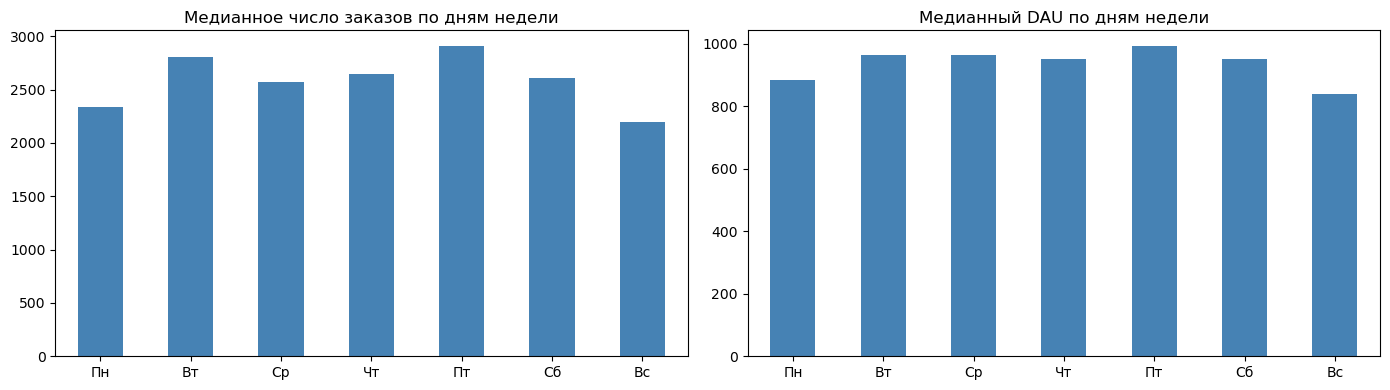

In [29]:
# Новое поле - день недели
daily_df['weekday'] = daily_df.index.dayofweek
# выделяем выходные и будни в новом поле 'day_type'
day_map = {0: 'будни', 1: 'будни', 2: 'будни', 3: 'будни', 4: 'будни',
           5: 'выходные', 6: 'выходные'}
# Новое поле - тип дня недели
daily_df['day_type'] = daily_df['weekday'].map(day_map)

cols = ['orders', 'dau', 'orders_per_user', 'avg_ticket_price']

by_weekday = daily_df.groupby('weekday')[cols].median().round(2)
by_weekday.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
display(by_weekday)
display(daily_df.groupby('day_type')[cols].median().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_weekday['orders'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Медианное число заказов по дням недели')
by_weekday['dau'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Медианный DAU по дням недели')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

#### 3.2.4. Промежуточный вывод по разделу 3.2 
**Динамика за сентябрь-октябрь.**
- Число заказов и DAU растут: в среднем за первую неделю сентября было около 2 230 заказов и 714 активных пользователей в день, за последнюю неделю октября — около 3 640 заказов и 1 097 пользователей. Медианный DAU вырос с 819 в первые 30 дней до 1 025 в оставшиеся дни.
- Среднее число заказов на одного пользователя в обычные дни стабильно: медиана 2,78.
- Средняя выручка с одного билета держится около 183 руб. (медиана 187 руб.) без выраженного тренда.

**Аномальные дни.** Три дня резко выбиваются по числу заказов: 3 сентября (5 111), 1 октября (7 288) и 31 октября (5 961). В первых двух 67-72% заказов — спорт, около 65-70% приходится на Медовскую область, а 67-73% — на оператора «Билеты в руки». В эти дни число заказов на пользователя вырастает до 6,6, а средняя выручка с билета падает до 80 руб. (3 сентября). Это похоже на массовую продажу дешёвых билетов на спортивные события одним партнёром. 31 октября пик другой природы: 66% заказов — концерты, 59% — Каменевский регион. Эти дни искажают средние значения, поэтому далее используются медианы. Пики спортивных заказов также объясняют рост доли спорта осенью и часть снижения средней стоимости билета.

**Недельная цикличность.** Пользователи активнее в будни, чем в выходные: медианное число заказов 2 716 против 2 435, DAU 958 против 890. Самый слабый день — воскресенье (2 198 заказов, DAU 840), самый сильный — пятница (2 910 заказов, DAU 994). При этом в выходные билеты в среднем дороже (около 199 руб. против 184 руб. в будни).

### 3.3. Популярные события и партнёры
#### 3.3.1. Распределение мероприятий и заказов по регионам
Для каждого региона считаем число уникальных мероприятий и заказов, а также их доли от общего числа (по всему периоду).

Топ 5 регионов по количеству мероприятий


,events,orders,"доля_региона_по_мероприятиям, %","доля_региона_по_заказам, %"
region_name,,,,
Каменевский регион,5935,89665,26.54,31.16
Североярская область,3800,43739,17.00,15.20
Широковская область,1232,16169,5.51,5.62
Светополянский округ,1075,7502,4.81,2.61
Речиновская область,702,6267,3.14,2.18


Топ 5 регионов по количеству заказов


,events,orders,"доля_региона_по_мероприятиям, %","доля_региона_по_заказам, %"
region_name,,,,
Каменевский регион,5935,89665,26.54,31.16
Североярская область,3800,43739,17.00,15.20
Широковская область,1232,16169,5.51,5.62
Медовская область,504,13892,2.25,4.83
Озернинский край,349,10405,1.56,3.62


Регионов: 81
Доля топ-3 по мероприятиям, %: 49.0
Доля топ-3 по заказам, %: 52.0


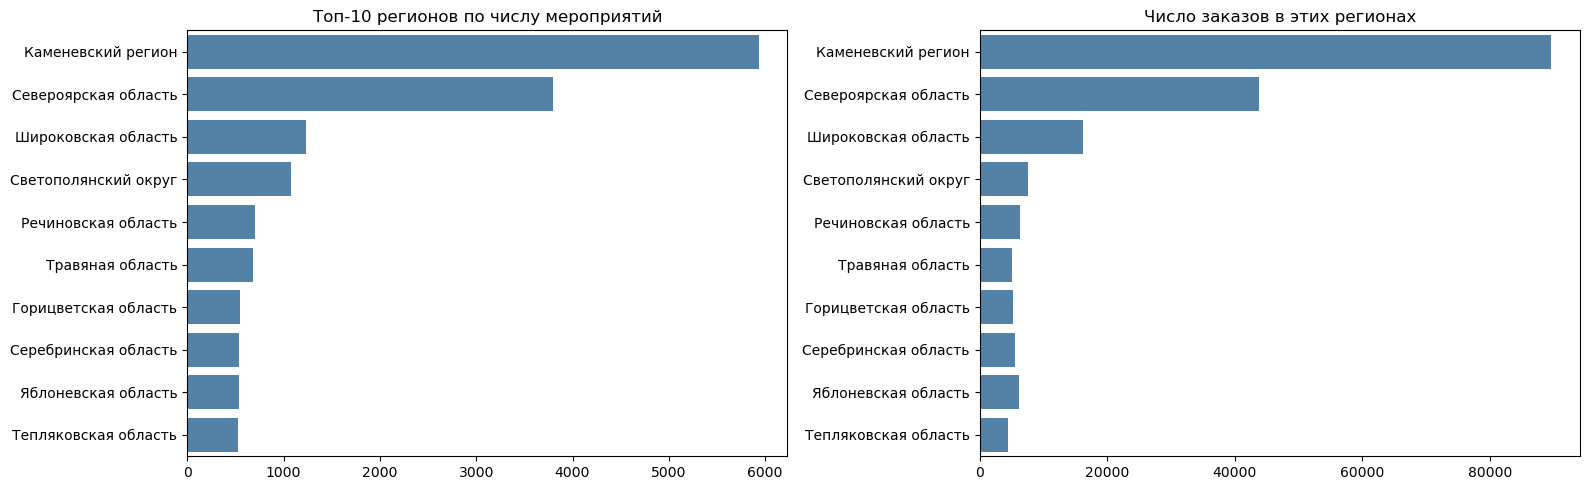

In [30]:
# Создаем промежуточный датафрейм regions с требуемыми агрегациями
regions = df.groupby('region_name').agg(events=('event_id', 'nunique'),
                                        orders=('order_id', 'count'))
regions['доля_региона_по_мероприятиям, %'] = regions['events'] / df['event_id'].nunique() * 100
regions['доля_региона_по_заказам, %'] = regions['orders'] / len(df) * 100
regions = regions.sort_values('events', ascending=False)
print('Топ 5 регионов по количеству мероприятий')
display(regions.head(5).round(2))
print('Топ 5 регионов по количеству заказов')
display(regions.sort_values('orders', ascending=False).head(5).round(2))

print('Регионов:', len(regions))
print('Доля топ-3 по мероприятиям, %:', regions['доля_региона_по_мероприятиям, %'].head(3).sum().round(1))
print('Доля топ-3 по заказам, %:', regions.sort_values('orders', ascending=False)['доля_региона_по_заказам, %'].head(3).sum().round(1))

top_regions = regions.head(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_regions['events'], y=top_regions.index, color='steelblue', ax=axes[0])
axes[0].set_title('Топ-10 регионов по числу мероприятий')
sns.barplot(x=top_regions['orders'], y=top_regions.index, color='steelblue', ax=axes[1])
axes[1].set_title('Число заказов в этих регионах')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

#### 3.3.2. Распределение по билетным партнёрам
Для каждого билетного оператора считаем число уникальных мероприятий, заказов и суммарную выручку в рублях, а также доли от общих значений.

Топ 5 партнеров по суммарной выручке


,events,orders,revenue,"доля_партнера_по_заказам, %","доля_партнера_по_выручке, %"
service_name,,,,,
Билеты без проблем,4247,62858,24322192.40,21.84,16.30
Мой билет,1300,34440,22042364.72,11.97,14.77
Облачко,2335,26402,18588613.86,9.18,12.45
Лови билет!,4867,40802,16675475.08,14.18,11.17
Весь в билетах,855,16425,16533231.19,5.71,11.08


Партнёров: 36
Партнёров с долей заказов меньше 1%: 24
Суммарная выручка, млн руб.: 149.3
Доля топ-5 по выручке, %: 65.8
Доля топ-5 по заказам, %: 71.2


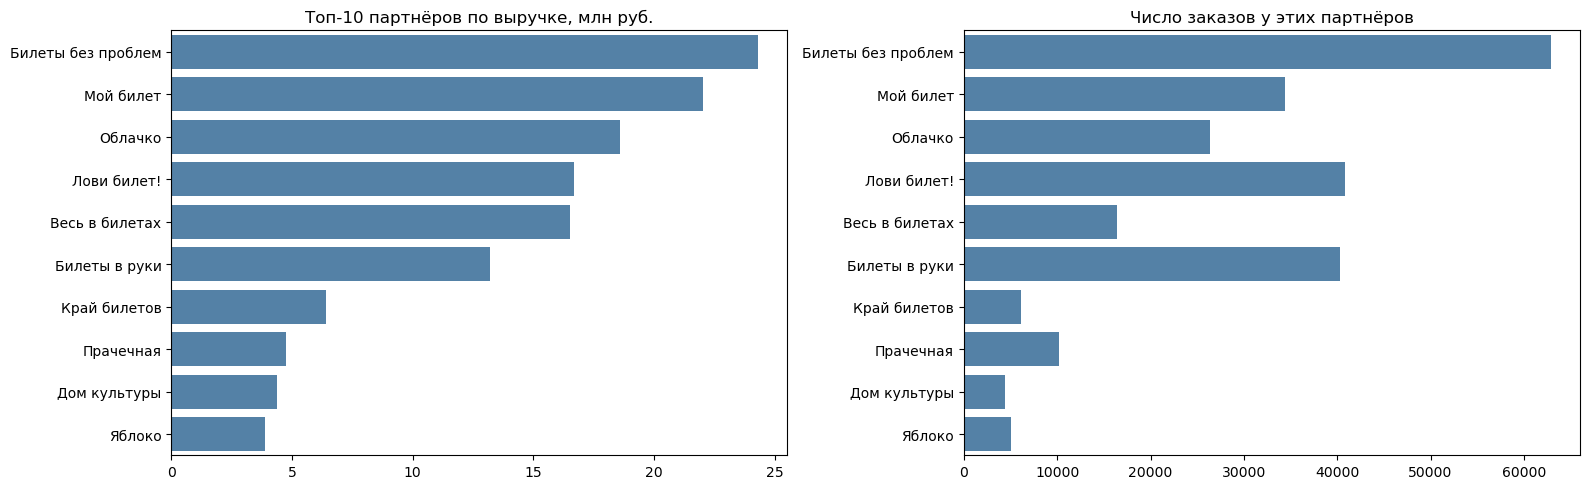

In [31]:
# Создаем новый датафрейм парнеры(partners)
partners = df.groupby('service_name').agg(events=('event_id', 'nunique'),
                                         orders=('order_id', 'count'),
                                         revenue=('revenue_rub', 'sum'))
partners['доля_партнера_по_заказам, %'] = partners['orders'] / len(df) * 100
partners['доля_партнера_по_выручке, %'] = partners['revenue'] / df['revenue_rub'].sum() * 100
partners = partners.sort_values('revenue', ascending=False)
print('Топ 5 партнеров по суммарной выручке')
display(partners.head(5).round(2))

print('Партнёров:', len(partners))
print('Партнёров с долей заказов меньше 1%:', (partners['доля_партнера_по_заказам, %'] < 1).sum())
print('Суммарная выручка, млн руб.:', round(df['revenue_rub'].sum() / 1e6, 1))
print('Доля топ-5 по выручке, %:', partners['доля_партнера_по_выручке, %'].head(5).sum().round(1))
print('Доля топ-5 по заказам, %:', partners['доля_партнера_по_заказам, %'].sort_values(ascending=False).head(5).sum().round(1))
# Ограничим отрисовку десятью партнерами
top_partners = partners.head(10)
# Отрисовка
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_partners['revenue'] / 1e6, y=top_partners.index, color='steelblue', ax=axes[0])
axes[0].set_title('Топ-10 партнёров по выручке, млн руб.')
sns.barplot(x=top_partners['orders'], y=top_partners.index, color='steelblue', ax=axes[1])
axes[1].set_title('Число заказов у этих партнёров')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

#### 3.3.3. Промежуточный вывод по разделу 3.3

**Регионы.** Данные охватывают 81 регион, но мероприятия и заказы сильно сконцентрированы. На три региона приходится 49,0% всех мероприятий и 52,0% заказов. Явные лидеры — Каменевский регион (5 935 мероприятий, 26,5%; 89 662 заказов, 31,2%) и Североярская область (3 800 мероприятий, 17,0%; 43 738 заказов, 15,2%), третье место занимает Широковская область (5,5% мероприятий, 5,6% заказов). По всей видимости, данные регионы имеют `большую плотность` населения. Остальные регионы дают небольшие доли, и ни один из них не выходит за 5% мероприятий. Отдельно выделяется Медовская область: при небольшом числе мероприятий (504, 2,3%) в ней 13 892 заказа (4,8%), то есть на одно мероприятие приходится заметно больше заказов, чем в среднем.

**Партнёры.** В данных 36 билетных операторов. На пятёрку лидеров приходится 65,8% выручки и 71,2% заказов. По выручке лидирует «Билеты без проблем» (24,3 млн руб., 16,3% выручки, 21,8% заказов), за ним идут «Мой билет» (22,0 млн руб., 14,8%), «Облачко» (18,6 млн руб., 12,5%), «Лови билет!» (16,7 млн руб., 11,2%) и «Весь в билетах» (16,5 млн руб., 11,1%). «Лови билет!» работает с наибольшим числом мероприятий (4 867). У операторов разный средний чек: у «Билеты в руки» доля заказов (14,0%) заметно выше доли выручки (8,9%) — это оператор дешёвых билетов, а у «Мой билет» наоборот (12,0% заказов и 14,8% выручки). 24 из 36 операторов дают менее 1% заказов каждый (вместе около 6%).

**Вывод.** Рынок неравномерен: два региона и несколько партнёров формируют большую часть заказов и выручки. Разнообразие мероприятий выше всего в Каменевском регионе и Североярской области.

## Шаг 4. Статистический анализ данных
### 4.1. Подготовка данных
Проверяем две гипотезы об отличии поведения пользователей мобильных и стационарных устройств. Используем только осенние данные. Единица анализа — пользователь. Чтобы группы были независимыми, исключаем пользователей, которые осенью заказывали с обоих типов устройств. Уровень значимости принимаем равным 0,05.

In [32]:
# Уровень значимости
alpha = 0.05
# Создаем датафрейм с сезоном "осень" как требуется в ТЗ
autumn = df[df['season'] == 'осень']

# пользователи, которые заказывали с двух типов устройств
devices_per_user = autumn.groupby('user_id')['device_type_canonical'].nunique()
both_devices = (devices_per_user > 1).sum()
print(f'Пользователей осенью: {len(devices_per_user)}')
print(f'Пользовались обоими устройствами: {both_devices} ({both_devices / len(devices_per_user):.1%})')
# Фильтруем на пользователей, которые пользовались только одним устройством
single_users = devices_per_user[devices_per_user == 1].index
autumn_single = autumn[autumn['user_id'].isin(single_users)]
print('Пользователи, которые использовали только одно устройство')
print(autumn_single.groupby('device_type_canonical')['user_id'].nunique())

Пользователей осенью: 15811
Пользовались обоими устройствами: 3249 (20.5%)
Пользователи, которые использовали только одно устройство
device_type_canonical
desktop     1619
mobile     10943
Name: user_id, dtype: int64


### 4.2. Гипотеза 1: число заказов на одного пользователя

**Н0:** среднее число заказов на одного пользователя мобильных устройств не больше чем для стационарных устройств.  
**Н1:** среднее число заказов на одного пользователя мобильных устройств больше.

Сначала смотрим на распределения.

,count,mean,std,min,50%,90%,99%,max
device_type_canonical,,,,,,,,
desktop,1619.0,1.97,3.06,1.0,1.0,3.0,12.0,56.0
mobile,10943.0,2.86,4.10,1.0,2.0,6.0,20.0,123.0


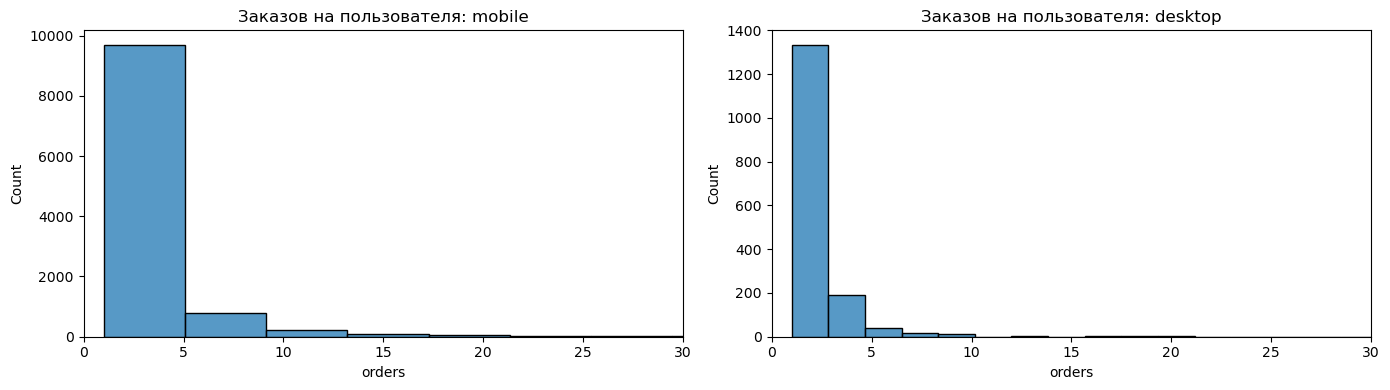

In [33]:
user_orders = (autumn_single.groupby(['user_id', 'device_type_canonical'])['order_id']
               .count().reset_index(name='orders'))
display(user_orders.groupby('device_type_canonical')['orders'].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for dev, ax in zip(['mobile', 'desktop'], axes):
    sns.histplot(user_orders.loc[user_orders['device_type_canonical'] == dev, 'orders'], bins=30, ax=ax)
    ax.set_title(f'Заказов на пользователя: {dev}')
    ax.set_xlim(0, 30)
plt.tight_layout()
plt.show()

**Выбор теста.** Гипотеза о средних, группы независимы (пользователи не пересекаются) и большие (тысячи наблюдений), поэтому по центральной предельной теореме подходит t-тест. Однако размеры групп сильно различаются и надо сравнить дисперсии групп с помощью тест Левена для принятия решения какой тест использовать: обычный(при равенстве дисперсий) или t-тест Уэлча(при неравенстве дисперсий).

In [34]:
mobile_orders = user_orders.loc[user_orders['device_type_canonical'] == 'mobile', 'orders']
desktop_orders = user_orders.loc[user_orders['device_type_canonical'] == 'desktop', 'orders']
print('Тест Левена:', stats.levene(mobile_orders, desktop_orders))

Тест Левена: LeveneResult(statistic=np.float64(78.92104718741743), pvalue=np.float64(7.336469977392343e-19))


Видим, что `pvalue` занчительно меньше `0,05`, значит применим `t-тест Уэлча`(`equal_var=False`) с односторонней альтернативой. Для проверки устойчивости результата дополнительно применяем непараметрический тест Манна-Уитни.

In [35]:
t_res = stats.ttest_ind(mobile_orders, desktop_orders, equal_var=False, alternative='greater')
u_res = stats.mannwhitneyu(mobile_orders, desktop_orders, alternative='greater')
print(f'Среднее: mobile {mobile_orders.mean():.2f}, desktop {desktop_orders.mean():.2f}')
print(f'Welch t-test: p-value = {t_res.pvalue:.2e}')
print(f'Mann-Whitney U: p-value = {u_res.pvalue:.2e}')
print('Отвергаем H0' if t_res.pvalue < alpha else 'Не отвергаем H0')

Среднее: mobile 2.86, desktop 1.97
Welch t-test: p-value = 4.64e-25
Mann-Whitney U: p-value = 3.74e-39
Отвергаем H0


По результатам тестов в обоих случаях **отвергаем нулевую гипотезу**, так как pvalue значительно меньше уровня значимости 0,05. Следовательно можно предположить с большой долей вероятности, что среднее число заказов на одного пользователя мобильных устройств больше.

### 4.3. Гипотеза 2: время между заказами

**Н0:** среднее время между заказами пользователей мобильных не больше чем для стационарных устройств.  
**Н1:** среднее время между заказами пользователей мобильных устройств больше.

Для каждого пользователя считаем среднее значение `days_since_prev` (пропуски — первые заказы — не учитываются).

,count,mean,std,min,50%,90%,99%,max
device_type_canonical,,,,,,,,
desktop,894.0,31.36,36.56,0.0,16.0,87.0,130.00,146.0
mobile,7057.0,25.25,30.20,0.0,14.0,69.7,126.44,148.0


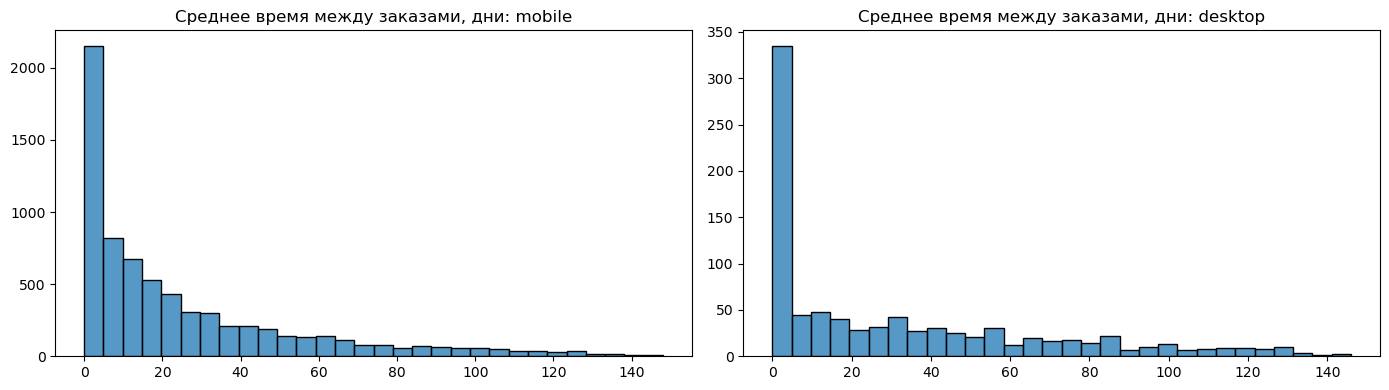

In [36]:
user_gap = (autumn_single.dropna(subset=['days_since_prev'])
            .groupby(['user_id', 'device_type_canonical'])['days_since_prev']
            .mean().reset_index())
display(user_gap.groupby('device_type_canonical')['days_since_prev'].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for dev, ax in zip(['mobile', 'desktop'], axes):
    sns.histplot(user_gap.loc[user_gap['device_type_canonical'] == dev, 'days_since_prev'], bins=30, ax=ax)
    ax.set_title(f'Среднее время между заказами, дни: {dev}')
    ax.set_xlabel('') 
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Выбор теста.** Логика та же, что и в первой гипотезе: независимые большие группы, скошенные распределения и разные дисперсии — применяем t-тест Уэлча с односторонней альтернативой, а для проверки устойчивости — тест Манна-Уитни.

In [37]:
mobile_gap = user_gap.loc[user_gap['device_type_canonical'] == 'mobile', 'days_since_prev']
desktop_gap = user_gap.loc[user_gap['device_type_canonical'] == 'desktop', 'days_since_prev']
print('Тест Левена:', stats.levene(mobile_gap, desktop_gap))

t_res = stats.ttest_ind(mobile_gap, desktop_gap, equal_var=False, alternative='greater')
u_res = stats.mannwhitneyu(mobile_gap, desktop_gap, alternative='greater')
print(f'Среднее: mobile {mobile_gap.mean():.2f}, desktop {desktop_gap.mean():.2f}')
print(f'Медиана: mobile {mobile_gap.median():.1f}, desktop {desktop_gap.median():.1f}')
print(f'Welch t-test: p-value = {t_res.pvalue:.4f}')
print(f'Mann-Whitney U: p-value = {u_res.pvalue:.4f}')
print('Отвергаем H0' if t_res.pvalue < alpha else 'Не отвергаем H0')

Тест Левена: LeveneResult(statistic=np.float64(69.52340874687715), pvalue=np.float64(8.821401110905379e-17))
Среднее: mobile 25.25, desktop 31.36
Медиана: mobile 14.0, desktop 16.0
Welch t-test: p-value = 1.0000
Mann-Whitney U: p-value = 0.7933
Не отвергаем H0


В обоих тестах pvalue занчительно выше порога значимости 0,05. **Нулевую гипотезу не отвергаем.**

### 4.4. Промежуточный вывод по проверке гипотез

Из 15 808 осенних пользователей 3 248 (20,5%) пользовались обоими типами устройств, их исключили.  
В анализе остались 10 940 пользователей мобильных и 1 620 пользователей стационарных устройств.

**Гипотеза 1 подтверждена.** Мобильные пользователи в среднем делают 2,86 заказа за осень, пользователи стационарных устройств — 1,97 (медианы 2 и 1). Оба теста дают p-value существенно ниже 0,05 (t-тест Уэлча: 7,4e-25, Манна-Уитни: 4,7e-39), нулевую гипотезу отвергаем: пользователи мобильных устройств заказывают чаще.

**Гипотеза 2 не подтверждена.** Среднее время между заказами у мобильных пользователей составляет 25,3 дня (медиана 14), у пользователей стационарных устройств — 31,4 дня (медиана 16), то есть у мобильных оно `не больше, а меньше`. P-value в обоих тестах (около 1,0 и 0,80) намного выше 0,05, поэтому нулевую гипотезу не отвергаем. Полученные результаты согласуются с первой гипотезой: мобильные пользователи не только заказывают больше, но и возвращаются быстрее.

# Общий вывод и рекомендации

**Данные.** Исследованы заказы билетов Яндекс Афиши с 1 июня по 31 октября 2024 года с мобильных и стационарных устройств, информация о мероприятиях и курс тенге. После предобработки (удалены 238 заказов на фильмы, 40 неявных дубликатов и 2 885 выбросов выручки по 99-му процентилю, выручка в тенге переведена в рубли) осталось 287 686 заказов (98,9% от исходных). Выручка составила около 149 млн руб.

**Основные результаты.**
- **Рост спроса.** Число заказов выросло с 34 тыс. в июне до 99 тыс. в октябре, особенно резко в сентябре (+56%) и октябре (+43%). Среднее число заказов в день растёт: DAU вырос примерно с 700 до 1 100 пользователей.
- **Востребованные мероприятия.** Концерты остаются самым популярным типом (37% заказов осенью), затем театр (25%). Осенью заметно выросли доли спорта (2,5% -> 11,2%), театра (20,1% -> 25,3%) и детских мероприятий (0+: 18,0% -> 23,6%), снизились доли «другого» и концертов.
- **Средний чек.** Средняя выручка с билета упала на 15% (209 -> 178 руб.). Подешевели билеты на театр (-17,8%), ёлки (-15,4%) и концерты (-12,0%)
- **Активность пользователей.** Около 80% заказов делается с мобильных устройств. В будни активность выше, чем в выходные (медианно 2 716 против 2 435 заказов в день), самый слабый день — воскресенье. В сентябре-октябре выделяются три аномальных дня (3 сентября, 1 и 31 октября) с резким ростом заказов: в первых двух 65-70% заказов — спорт в Медовской области через оператора «Билеты в руки».
- **Регионы и партнёры.** Явные лидеры: Каменевский регион и Североярская область (около 46% заказов вместе). Пять партнёров приносят 66% выручки, лидирует «Билеты без проблем».

**Гипотезы.** Подтверждена гипотеза о том, что пользователи мобильных устройств делают больше заказов (2,86 против 1,97). Гипотеза о более длинных интервалах между заказами у мобильных пользователей не подтвердилась: они возвращаются в среднем быстрее (25,3 против 31,4 дня).

**Рекомендации.**
1. Приоритет — мобильный канал: на него приходится около 80% заказов, а его пользователи активнее. Нужно развивать мобильное приложение увеличивать лояльность клиентов именно в мобильных приложениях.
2. Контролировать всплески заказов. Дни с аномальной активностью (спорт, Медовская область, оператор «Билеты в руки») искажают средние показатели. Стоит выяснить причину (акция, массовая продажа и т. д.).
3. Есть большая зависимость от нескольких регионов: два региона дают около 46% заказов. Если эта зависимость связана с большой популяцие граждан в этих регионах, то нужно выходить на новые регионы с большой популяцией для генерации еще бОльшей выручки. Если это другая причина, необходимо диверсифицироваться по другим регионам с помощью рекламных акций и программ лояльности, чтобы выручка не зависела так сильно от этих двух регионов.
4. Есть большая зависимость от операторов. Пять операторов дают 66% выручки. Нужно диверсифицироваться по операторам: либо равномерно распределить по остальным заказы, либо привлечь новых операторов. Иначе такая большая зависимость от этой пятерки может привести к серьезным убыткам, в случае, например, банкротства одного из этих пятерых операторов.